
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# Vertices of Polytopes

**Prerequisites:** [Faces, Vertices, and Extreme Points](extreme-points-and-minkowski-theorem.ipynb) · [Polyhedra and Polytopes](polyhedra-and-polytopes.ipynb)

## 1\. A Polytope Is the Convex Hull of Finitely Many Points

::: {#thm-polytope-finite-hull}
## Polytopes Are Generated by Finite Sets

Every polytope $P = \{x \in \mathbb{R}^n : a_i^{\mathsf T}x \le b_i,\ i = 1, \dots, m\}$ is the convex hull of a finite set.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-polytope-finite-hull
If $P = \emptyset$, then $P = \operatorname{conv}\emptyset$. Let $P \ne \emptyset$; we use induction on $d = \dim P$. If $d = 0$, $P$ is a single point $p$ and $P = \operatorname{conv}\{p\}$.

Let $d \ge 1$. Let $I_0$ be the set of indices $i$ with $a_i^{\mathsf T}x = b_i$ for *all* $x \in P$, and for $i \notin I_0$ let
$$
F_i = \{x \in P : a_i^{\mathsf T}x = b_i\} .
$$
Each $F_i$ is a polytope (add the inequality $-a_i^{\mathsf T}x \le -b_i$). If $F_i \ne \emptyset$, then $a_i \ne 0$ (for $a_i = 0$, equality at one point means $b_i = 0$, and then it holds everywhere, i.e. $i \in I_0$), $P \not\subseteq H(a_i, b_i)$ since $i \notin I_0$, and so $\dim F_i \le d - 1$ by [this lemma](polyhedra-and-polytopes.ipynb#lem-dimension-drop). By induction $F_i = \operatorname{conv} V_i$ with $V_i$ finite (take $V_i = \emptyset$ if $F_i = \emptyset$). Let $V = \bigcup_{i \notin I_0} V_i$, a finite subset of $P$. Then $\operatorname{conv} V \subseteq P$; we show $P \subseteq \operatorname{conv} V$.

Let $x \in P$. Let $W \ne \{0\}$ be the direction of $\operatorname{aff} P$ and $u \in W \setminus \{0\}$. The set $T = \{t : x + tu \in P\}$ is a closed bounded interval $[t_-, t_+]$ containing $0$ ($P$ is closed, bounded, convex). Let $y = x + t_+u$. For $i \in I_0$ the equation $a_i^{\mathsf T}x = b_i$ holds on $P$, hence on $\operatorname{aff} P$ ([this lemma](polyhedra-and-polytopes.ipynb#lem-affine-hull)), so $a_i^{\mathsf T}(y + \varepsilon u) = b_i$ for all $\varepsilon$. If we had $a_i^{\mathsf T}y < b_i$ for every $i \notin I_0$, then, as there are finitely many such $i$, also $a_i^{\mathsf T}(y + \varepsilon u) < b_i$ for all small $\varepsilon > 0$; then $y + \varepsilon u \in P$, contradicting the maximality of $t_+$. So $a_i^{\mathsf T}y = b_i$ for some $i \notin I_0$, i.e. $y \in F_i \subseteq \operatorname{conv} V$. In the same way $z = x + t_-u \in \operatorname{conv} V$. Since $x$ lies on the segment $[z, y]$ and $\operatorname{conv} V$ is convex, $x \in \operatorname{conv} V$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: A Line Through a Point Ends on Facets
A line through $x$ inside $\operatorname{aff} P$ leaves $P$ where some inequality becomes an equation, so its two end points lie on lower-dimensional pieces $F_i$ of $P$; these are generated by finitely many points by induction, and $x$ lies between the two end points. The inequalities that are equations on all of $P$ (the set $I_0$) must be ignored: for them $F_i = P$, and there would be no drop in dimension.
:::

5 corners: [(-3.0, 2.0), (-1.0, -2.0), (3.2, -0.6), (4.4, 1.8), (1.2, 3.4)]


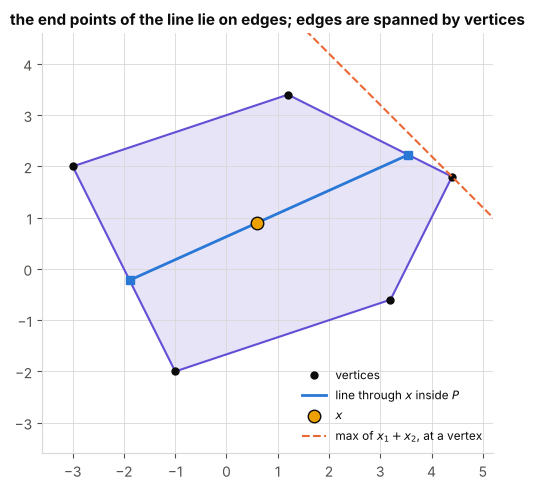

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from itertools import combinations
from scipy.spatial import ConvexHull

A = np.array([[1, 2], [2, -1], [-1, 3], [-2, -1], [1, -3], [-1, 0]], float)
b = np.array([8, 7, 9, 4, 5, 3], float)
# corners: points where two independent constraints are tight and all constraints hold
corners = []
for i, j in combinations(range(len(b)), 2):
    M = A[[i, j]]
    if abs(np.linalg.det(M)) > 1e-12:
        p = np.linalg.solve(M, b[[i, j]])
        if np.all(A @ p <= b + 1e-9):
            corners.append(p)
corners = np.unique(np.round(corners, 9), axis=0)
H = corners[ConvexHull(corners).vertices]
print(len(corners), "corners:", [tuple(float(v) for v in np.round(p, 3)) for p in H])

x = np.array([0.6, 0.9]); u = np.array([1.0, 0.45])
ts = []
for sgn in (+1, -1):          # largest t with x + t*sgn*u in P
    ratios = [(b[i] - A[i] @ x) / (A[i] @ (sgn * u)) for i in range(len(b)) if A[i] @ (sgn * u) > 1e-12]
    ts.append(sgn * min(ratios))
y, z = x + ts[0] * u, x + ts[1] * u

c = np.array([1.0, 1.0])
best = H[np.argmax(H @ c)]
fig, ax = plt.subplots(figsize=(6.6, 5))
ax.fill(*H.T, color=VIOLET, alpha=0.15); ax.plot(*np.vstack([H, H[:1]]).T, color=VIOLET)
ax.plot(*H.T, "o", color=INK, ms=5, label="vertices")
ax.plot(*np.c_[z, y], color=BLUE, lw=2, label="line through $x$ inside $P$")
ax.plot(*x, "o", color=YELLOW, mec=INK, ms=9, label="$x$")
ax.plot(*np.c_[y, z], "s", color=BLUE, ms=6)
t = np.linspace(-4, 6, 2); ax.plot(t, best @ c - t, color=ORANGE, ls="--", lw=1.5, label="max of $x_1 + x_2$, at a vertex")
ax.set_xlim(-3.6, 5.2); ax.set_ylim(-3.6, 4.6); ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("the end points of the line lie on edges; edges are spanned by vertices")
plt.tight_layout(); plt.show()


## 2\. Extreme Points of a Polytope Are Its Vertices

::: {#lem-finite-hull-compact}
## The Convex Hull of a Finite Set Is Compact

For $v_1, \dots, v_k \in \mathbb{R}^n$, the set $\operatorname{conv}\{v_1, \dots, v_k\}$ is compact.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-finite-hull-compact
By [the description of the hull](convex-sets-and-convex-hulls.ipynb#thm-convex-hull-equivalence) (repeated points may be merged, and missing points get coefficient $0$), the hull is the image of $\{\lambda \in \mathbb{R}^k : \lambda \ge 0, \sum\lambda_i = 1\}$ under the linear, hence continuous, map $\lambda \mapsto \sum \lambda_iv_i$. That set is closed and bounded, hence compact, and continuous images of compact sets are compact ([continuity and compactness](continuity-and-compactness.ipynb)). $\blacksquare$
:::

::: {#thm-polytope-vertices}
## Structure of Polytopes

Let $P$ be a nonempty polytope. Then

1. $P$ has finitely many extreme points, and $P = \operatorname{conv}(\operatorname{ext} P)$;
2. the extreme points of $P$ are exactly its vertices.

So a nonempty polytope is the convex hull of its finitely many vertices, and no smaller set generates it.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-polytope-vertices

1. By @thm-polytope-finite-hull, $P = \operatorname{conv} V$ with $V$ finite, so $\operatorname{ext} P \subseteq V$ by [this lemma](extreme-points-and-minkowski-theorem.ipynb#lem-extreme-not-in-hull), and $\operatorname{ext} P$ is finite. $P$ is closed and bounded, hence compact, so $P = \operatorname{conv}(\operatorname{ext} P)$ by [Minkowski's theorem](extreme-points-and-minkowski-theorem.ipynb#thm-minkowski).

2. Every vertex is extreme ([this proposition](extreme-points-and-minkowski-theorem.ipynb#prp-vertex-is-extreme)). Let $v \in \operatorname{ext} P$ and $E' = \operatorname{ext} P \setminus \{v\}$. If $E' = \emptyset$, then $P = \{v\}$ and any $a \ne 0$ shows that $v$ is a vertex. Otherwise $K = \operatorname{conv} E'$ is compact by @lem-finite-hull-compact, and $v \notin K$, since $K \subseteq \operatorname{conv}(P \setminus \{v\})$, which does not contain the extreme point $v$. By the [separation theorem](hyperplane-separation-theorems.ipynb#thm-separating-hyperplane) there is $a$ with $a^{\mathsf T}c < a^{\mathsf T}v$ for all $c \in K$.

Let $x \in P \setminus \{v\}$. By part 1, $x = t_vv + \sum_{e \in E'} t_ee$ with $t \ge 0$, $\sum t = 1$, and $t_v < 1$ since $x \ne v$. Then $c = \sum_{e \in E'}\frac{t_e}{1 - t_v}e \in K$ and $x = t_vv + (1 - t_v)c$, so
$$
a^{\mathsf T}x = t_v\,a^{\mathsf T}v + (1 - t_v)\,a^{\mathsf T}c < a^{\mathsf T}v .
$$
Hence $v$ is a vertex. $\blacksquare$
:::

::: {.callout-note}
## Why the Stadium Is Different
For the [stadium](extreme-points-and-minkowski-theorem.ipynb#exm-stadium), removing the extreme point $q$ leaves extreme points accumulating at $q$, so their convex hull is not closed, has $q$ on its boundary, and cannot be separated from $q$. For a polytope the remaining extreme points are finitely many, their hull is compact, and the separation is strict.
:::

::: {#cor-lp-optimum-at-vertex}
## Linear Functions Attain Their Maximum at a Vertex

Let $P$ be a nonempty polytope with vertex set $\{v_1, \dots, v_k\}$ and $c \in \mathbb{R}^n$. Then
$$
\max_{x \in P} c^{\mathsf T}x = \max_{1 \le i \le k} c^{\mathsf T}v_i,
$$
so an LP whose feasible set is a nonempty polytope has an optimal solution at a vertex.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-lp-optimum-at-vertex
Let $M = \max_i c^{\mathsf T}v_i$. Every $x \in P$ is $x = \sum t_iv_i$ with $t_i \ge 0$, $\sum t_i = 1$ (@thm-polytope-vertices), so $c^{\mathsf T}x = \sum t_i\,c^{\mathsf T}v_i \le M\sum t_i = M$, and $M$ is attained at a vertex. $\blacksquare$
:::

Thus optimizing over a polytope, an infinite set, reduces to a search among finitely many vertices. Since their number can be exponential in $n$, the search must be organized cleverly; this is what the [simplex method](simplex-method.ipynb) does.

## 3\. Examples

::: {#exm-vertices-three-families}
## Vertices of the Cube, the Cross-Polytope and the Simplex

1. The vertices of the [cube](polyhedra-and-polytopes.ipynb#exm-cube) $C_n = [-1,1]^n$ are the $2^n$ points of $\{-1, 1\}^n$.
2. The vertices of the [cross-polytope](polyhedra-and-polytopes.ipynb#exm-cross-polytope) $X_n$ are the $2n$ points $\pm e_1, \dots, \pm e_n$.
3. The vertices of the [simplex](polyhedra-and-polytopes.ipynb#exm-simplex) $\Delta_n$ are the $n + 1$ points $e_1, \dots, e_{n+1}$.
:::

::: {.callout-tip collapse="true"}
## Proof of @exm-vertices-three-families

1. For $v \in \{-1,1\}^n$ and $x \in C_n$, $v^{\mathsf T}x \le \sum |x_i| \le n = v^{\mathsf T}v$, with equality only if $v_ix_i = 1$ for all $i$, i.e. $x = v$; so $v$ is a vertex. If $x \in C_n$ has $|x_i| < 1$ for some $i$, then with $\delta = 1 - |x_i| > 0$ the points $x \pm \delta e_i$ lie in $C_n$ and $x$ is their midpoint, so $x$ is not extreme, hence not a vertex.
2. For $x \in X_n$, $\pm x_i \le \sum_j |x_j| \le 1$, with equality only for $x = \pm e_i$; so $\pm e_i$ are vertices. Every $x \in X_n$ is a convex combination of the points $\pm e_i$: with $s = \sum|x_i| \le 1$,
$$
x = \sum_{i} |x_i|\,(\operatorname{sign} x_i)\,e_i + \tfrac{1 - s}2\,e_1 + \tfrac{1 - s}2\,(-e_1),
$$
the coefficients being $\ge 0$ with sum $1$ (terms with $x_i = 0$ vanish). So $X_n = \operatorname{conv}\{\pm e_i\}$, and by [this lemma](extreme-points-and-minkowski-theorem.ipynb#lem-extreme-not-in-hull) there are no other extreme points.
3. Every $x \in \Delta_n$ equals $\sum x_ie_i$, a convex combination, so $\Delta_n = \operatorname{conv}\{e_1, \dots, e_{n+1}\}$ and $\operatorname{ext}\Delta_n \subseteq \{e_i\}$. Each $e_i$ is a vertex: $x_i \le 1 = e_i^{\mathsf T}e_i$ on $\Delta_n$, with equality only if $x = e_i$ (the other coordinates are $\ge 0$ and sum to $0$). $\blacksquare$
:::

::: {#exm-disc-not-polytope}
## A Disc Is Not a Polytope

Every point of the unit circle is an extreme point of the closed unit disc ([this example](extreme-points-and-minkowski-theorem.ipynb#exm-extreme-points)). A polytope has finitely many extreme points (@thm-polytope-vertices), so the disc is not a polytope; being bounded, it is not a polyhedron either.
:::